In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [10]:
!pip install datasets

from datasets import load_dataset

dataset = load_dataset("debojit01/fake-review-dataset")

df = dataset["train"].to_pandas()

print(df.head())

README.md:   0%|          | 0.00/2.79k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 8.25MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/40440 [00:00<?, ? examples/s]

             category  rating label  \
0  Home_and_Kitchen_5     5.0    CG   
1  Home_and_Kitchen_5     5.0    CG   
2  Home_and_Kitchen_5     5.0    CG   
3  Home_and_Kitchen_5     1.0    CG   
4  Home_and_Kitchen_5     5.0    CG   

                                               text_  text  
0  Love this!  Well made, sturdy, and very comfor...  None  
1  love it, a great upgrade from the original.  I...  None  
2  This pillow saved my back. I love the look and...  None  
3  Missing information on how to use it, but it i...  None  
4  Very nice set. Good quality. We have had the s...  None  


In [11]:
print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nReview Labels:")
print(df["label"].value_counts())

Dataset Shape:
(40440, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40440 entries, 0 to 40439
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   category  40432 non-null  object 
 1   rating    40432 non-null  float64
 2   label     40440 non-null  object 
 3   text_     40432 non-null  object 
 4   text      8 non-null      object 
dtypes: float64(1), object(4)
memory usage: 1.5+ MB
None

Missing Values:
category        8
rating          8
label           0
text_           8
text        40432
dtype: int64

Review Labels:
label
CG      20216
OR      20216
Real        8
Name: count, dtype: int64


In [12]:
df = df[["text_", "label"]]

df = df.dropna()

df["text_"] = df["text_"].astype(str)

df["label"] = df["label"].str.strip()

df = df[df["label"].isin(["CG", "OR"])]

print(df.head())

                                               text_ label
0  Love this!  Well made, sturdy, and very comfor...    CG
1  love it, a great upgrade from the original.  I...    CG
2  This pillow saved my back. I love the look and...    CG
3  Missing information on how to use it, but it i...    CG
4  Very nice set. Good quality. We have had the s...    CG


In [13]:
df["label"] = df["label"].map({
    "CG": 1,
    "OR": 0
})

print(df.head())

                                               text_  label
0  Love this!  Well made, sturdy, and very comfor...      1
1  love it, a great upgrade from the original.  I...      1
2  This pillow saved my back. I love the look and...      1
3  Missing information on how to use it, but it i...      1
4  Very nice set. Good quality. We have had the s...      1


In [14]:
X = df["text_"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

Training Data: 32345
Testing Data: 8087


In [15]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Text Vectorization Completed")

Text Vectorization Completed


In [16]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

print("Model Training Completed")

Model Training Completed


In [17]:
y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 86.74415728947695 %

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.87      0.87      4044
           1       0.87      0.86      0.87      4043

    accuracy                           0.87      8087
   macro avg       0.87      0.87      0.87      8087
weighted avg       0.87      0.87      0.87      8087



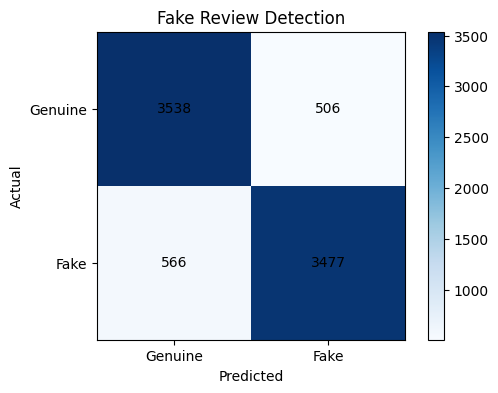

In [18]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))

plt.imshow(cm, cmap="Blues")

plt.title("Fake Review Detection")

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.colorbar()

plt.xticks([0,1], ["Genuine", "Fake"])
plt.yticks([0,1], ["Genuine", "Fake"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i,j],
                 ha="center", va="center")

plt.show()

In [19]:
review = input("Enter Your Review: ")

review_tfidf = tfidf.transform([review])

prediction = model.predict(review_tfidf)

if prediction[0] == 1:
    print("Result: Fake Review")
else:
    print("Result: Genuine Review")

Enter Your Review: *****
Result: Genuine Review
